In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import warnings

# Suppress warnings for clean output
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

# Define the exact folder path
folder_path = r"D:\Sachal\Raw Dataset\ipinyou.contest.dataset\training1st"
print("Libraries imported and path defined successfully.")

Libraries imported and path defined successfully.


In [3]:
print("Loading TRAINING Data (March 11)...")

# Load Impressions (State 0)
imp_file = os.path.join(folder_path, "imp.20130311.txt.bz2")
imp_train = pd.read_csv(imp_file, sep='\t', header=None, usecols=[1, 3, 19, 20], compression='bz2')
imp_train.columns = ['timestamp', 'user_id', 'bid_price', 'region_id']
imp_train['state'] = 0

# Load Clicks (State 1)
clk_file = os.path.join(folder_path, "clk.20130311.txt.bz2")
clk_train = pd.read_csv(clk_file, sep='\t', header=None, usecols=[1, 3], compression='bz2')
clk_train.columns = ['timestamp', 'user_id']
clk_train['state'] = 1
clk_train['region_id'] = 'Unknown'

print(f"Data Loaded: {len(imp_train):,} Impressions | {len(clk_train):,} Clicks")

Loading TRAINING Data (March 11)...
Data Loaded: 1,199,172 Impressions | 925 Clicks


In [4]:
print("Building chronological timelines...")

# Combine and sort
combined_train = pd.concat([imp_train, clk_train], ignore_index=True)
combined_train = combined_train.sort_values(by=['user_id', 'timestamp']).reset_index(drop=True)

# Shift to get next state
combined_train['next_state'] = combined_train.groupby('user_id')['state'].shift(-1)

# Drop the last row for each user and convert to int
valid_trans = combined_train.dropna(subset=['next_state']).copy()
valid_trans['next_state'] = valid_trans['next_state'].astype(int)

print(f"Timelines built. Total valid state transitions: {len(valid_trans):,}")

Building chronological timelines...
Timelines built. Total valid state transitions: 266,714


In [5]:
# RQ1: Global 2x2 Matrix
global_matrix = pd.crosstab(valid_trans['state'], valid_trans['next_state'], normalize='index')

print("=== RQ1: GLOBAL TRANSITION MATRIX ===")
print(global_matrix.round(4))

# RQ2: Regional Analysis (Min 1000 exposures)
region_analysis = valid_trans[(valid_trans['state'] == 0) & (valid_trans['region_id'] != 'Unknown')]
region_results = pd.DataFrame({
    'click_prob_0_to_1': region_analysis.groupby('region_id')['next_state'].mean(),
    'total_exposures': region_analysis.groupby('region_id').size()
})
reliable_regions = region_results[region_results['total_exposures'] >= 1000].sort_values(by='click_prob_0_to_1', ascending=False)

print("\n=== RQ2: TOP 5 REGIONS ===")
print(reliable_regions.head(5).round(4))

=== RQ1: GLOBAL TRANSITION MATRIX ===
next_state       0       1
state                     
0           0.9969  0.0031
1           0.4700  0.5300

=== RQ2: TOP 5 REGIONS ===
           click_prob_0_to_1  total_exposures
region_id                                    
144                   0.0065             4018
100                   0.0064             1255
53                    0.0056             3019
128                   0.0054             2964
32                    0.0053             1322


In [6]:
# Statistical Test (Chi-Square)
raw_counts = pd.crosstab(valid_trans['state'], valid_trans['next_state'])
chi2, p_value, dof, expected = chi2_contingency(raw_counts)

print("=== STATISTICAL SIGNIFICANCE ===")
print(f"P-value: {p_value:.4e} (Significant if < 0.05)")

# Financial Translation
avg_bid = imp_train['bid_price'].mean() / 1000.0
p_cold = global_matrix.loc[0, 1]
p_warm = global_matrix.loc[1, 1]

cpc_cold = avg_bid / p_cold
cpc_warm = avg_bid / p_warm
cac_reduction = cpc_cold / cpc_warm

print("\n=== RQ3: FINANCIAL TRANSLATION ===")
print(f"Average Bid Price: {avg_bid:.4f} RMB")
print(f"Cost Per Click (Cold): {cpc_cold:.2f} RMB")
print(f"Cost Per Click (Warm): {cpc_warm:.2f} RMB")
print(f"CAC Reduction: {cac_reduction:.1f}x")

=== STATISTICAL SIGNIFICANCE ===
P-value: 0.0000e+00 (Significant if < 0.05)

=== RQ3: FINANCIAL TRANSLATION ===
Average Bid Price: 0.3000 RMB
Cost Per Click (Cold): 98.02 RMB
Cost Per Click (Warm): 0.57 RMB
CAC Reduction: 173.2x


In [7]:
print("Loading TESTING Data (March 12)...")

# Load Test Data
imp_test = pd.read_csv(os.path.join(folder_path, "imp.20130312.txt.bz2"), sep='\t', header=None, usecols=[1, 3], compression='bz2')
imp_test.columns = ['timestamp', 'user_id']
imp_test['state'] = 0

clk_test = pd.read_csv(os.path.join(folder_path, "clk.20130312.txt.bz2"), sep='\t', header=None, usecols=[1, 3], compression='bz2')
clk_test.columns = ['timestamp', 'user_id']
clk_test['state'] = 1

# Build Transitions
combined_test = pd.concat([imp_test, clk_test], ignore_index=True)
combined_test = combined_test.sort_values(by=['user_id', 'timestamp']).reset_index(drop=True)
combined_test['next_state'] = combined_test.groupby('user_id')['state'].shift(-1)
valid_trans_test = combined_test.dropna(subset=['next_state']).copy()
valid_trans_test['next_state'] = valid_trans_test['next_state'].astype(int)

# Test Matrix & Error
test_matrix = pd.crosstab(valid_trans_test['state'], valid_trans_test['next_state'], normalize='index')
error = abs(global_matrix.loc[0, 1] - test_matrix.loc[0, 1])

print("\n=== RQ4: OUT-OF-SAMPLE VALIDATION ===")
print(f"Train Click Prob (0->1): {global_matrix.loc[0, 1]:.4f}")
print(f"Test Click Prob (0->1):  {test_matrix.loc[0, 1]:.4f}")
print(f"Absolute Prediction Error: {error:.4f}")

# Machine Learning Metrics
valid_trans_test['predicted'] = valid_trans_test.apply(lambda r: 1 if r['state'] == 1 else 0, axis=1)
y_true = valid_trans_test['next_state']
y_pred = valid_trans_test['predicted']

print("\n=== ML PREDICTION METRICS ===")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")

Loading TESTING Data (March 12)...

=== RQ4: OUT-OF-SAMPLE VALIDATION ===
Train Click Prob (0->1): 0.0031
Test Click Prob (0->1):  0.0034
Absolute Prediction Error: 0.0004

=== ML PREDICTION METRICS ===
Accuracy:  0.9964
Precision: 0.5326
Recall:    0.0570
F1-Score:  0.1029


Generating publication charts...


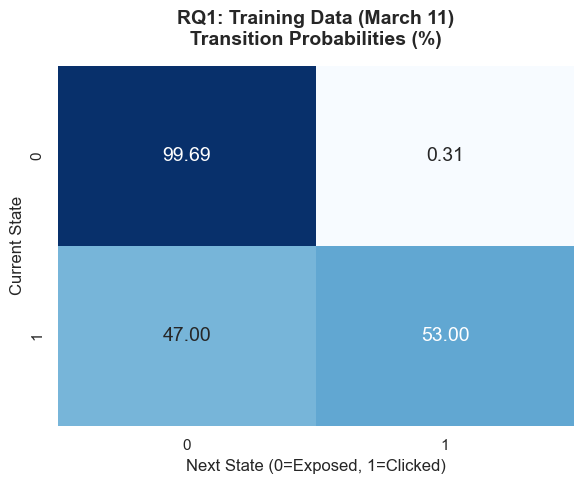

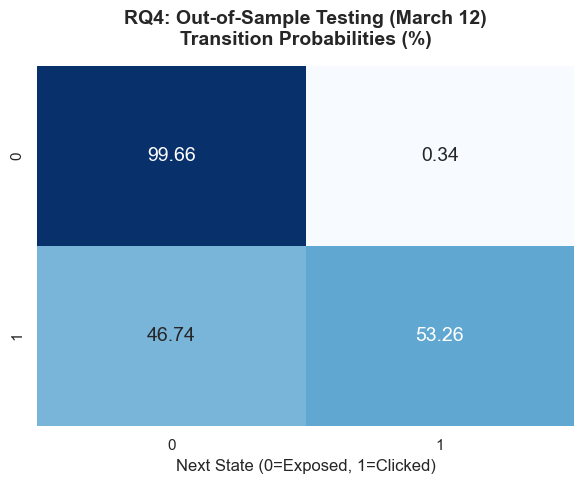

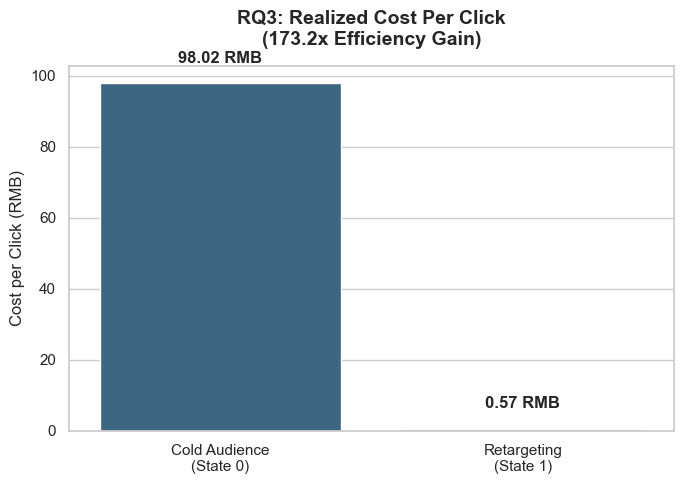

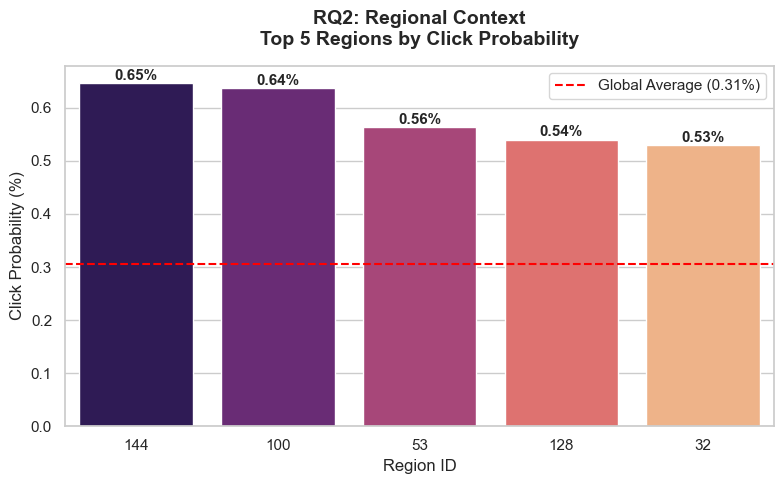


All 4 Publication Charts generated and saved to your folder!


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generating publication charts...")

# ---------------------------------------------------------
# FIGURE 1 (RQ1): Training Data Transition Matrix
# ---------------------------------------------------------
plt.figure(figsize=(6, 5))
sns.heatmap(global_matrix * 100, annot=True, fmt=".2f", cmap="Blues", 
            cbar=False, annot_kws={"size": 14})
plt.title("RQ1: Training Data (March 11)\nTransition Probabilities (%)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Next State (0=Exposed, 1=Clicked)", fontsize=12)
plt.ylabel("Current State", fontsize=12)
plt.tight_layout()
plt.savefig('Figure_RQ1_Training_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# FIGURE 2 (RQ4): Testing Data Transition Matrix
# ---------------------------------------------------------
plt.figure(figsize=(6, 5))
sns.heatmap(test_matrix * 100, annot=True, fmt=".2f", cmap="Blues", 
            cbar=False, annot_kws={"size": 14})
plt.title("RQ4: Out-of-Sample Testing (March 12)\nTransition Probabilities (%)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Next State (0=Exposed, 1=Clicked)", fontsize=12)
plt.ylabel("")
plt.tight_layout()
plt.savefig('Figure_RQ4_Testing_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# FIGURE 3 (RQ3): SME Strategic Insight (CPC Comparison)
# ---------------------------------------------------------
plt.figure(figsize=(7, 5))
states = ['Cold Audience\n(State 0)', 'Retargeting\n(State 1)']
cpc_values = [cpc_cold, cpc_warm]

sns.barplot(x=states, y=cpc_values, hue=states, palette="viridis", legend=False)
plt.title(f"RQ3: Realized Cost Per Click\n({cac_reduction:.1f}x Efficiency Gain)", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Cost per Click (RMB)", fontsize=12)

for i, v in enumerate(cpc_values):
    plt.text(i, v + (max(cpc_values)*0.05), f"{v:.2f} RMB", ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('Figure_RQ3_SME_Strategy.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# FIGURE 4 (RQ2): Regional Context (Top 5 Regions)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
top_regions = reliable_regions.head(5).reset_index()
top_regions['region_id'] = top_regions['region_id'].astype(str)
top_regions['click_prob_pct'] = top_regions['click_prob_0_to_1'] * 100

sns.barplot(data=top_regions, x='region_id', y='click_prob_pct', hue='region_id', palette="magma", legend=False)
plt.title("RQ2: Regional Context\nTop 5 Regions by Click Probability", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Region ID", fontsize=12)
plt.ylabel("Click Probability (%)", fontsize=12)

plt.axhline(y=global_matrix.loc[0, 1] * 100, color='red', linestyle='--', label=f'Global Average ({global_matrix.loc[0, 1]*100:.2f}%)')
plt.legend(loc='upper right')

for i, v in enumerate(top_regions['click_prob_pct']):
    plt.text(i, v + 0.0005, f"{v:.2f}%", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('Figure_RQ2_Regional_Context.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nAll 4 Publication Charts generated and saved to your folder!")

In [9]:
import pandas as pd
import numpy as np
import os

print("Calculating 3-State Model (Marketing to Operations)...")

# 1. Load Conversion Data for March 11
conv_file = os.path.join(folder_path, "conv.20130311.txt.bz2")
conv_train = pd.read_csv(conv_file, sep='\t', header=None, usecols=[1, 3], compression='bz2')
conv_train.columns = ['timestamp', 'user_id']
conv_train['state'] = 2 # State 2 = Converted
conv_train['region_id'] = 'Unknown'

# 2. Combine all 3 states
combined_3state = pd.concat([imp_train, clk_train, conv_train], ignore_index=True)

# 3. Sort and extract transitions
combined_3state = combined_3state.sort_values(by=['user_id', 'timestamp']).reset_index(drop=True)
combined_3state['next_state'] = combined_3state.groupby('user_id')['state'].shift(-1)
valid_trans_3state = combined_3state.dropna(subset=['next_state']).copy()
valid_trans_3state['next_state'] = valid_trans_3state['next_state'].astype(int)

# 4. Create 3x3 Matrix
matrix_3x3 = pd.crosstab(valid_trans_3state['state'], valid_trans_3state['next_state'], normalize='index')
matrix_3x3 = matrix_3x3.reindex(index=[0, 1, 2], columns=[0, 1, 2]).fillna(0)

print("3-State Matrix Calculated.")
print(matrix_3x3.round(4))

Calculating 3-State Model (Marketing to Operations)...
3-State Matrix Calculated.
next_state       0       1       2
state                             
0           0.9969  0.0031  0.0000
1           0.4234  0.4775  0.0991
2           0.0000  0.0000  1.0000


Generating clean 3-State Diagram...


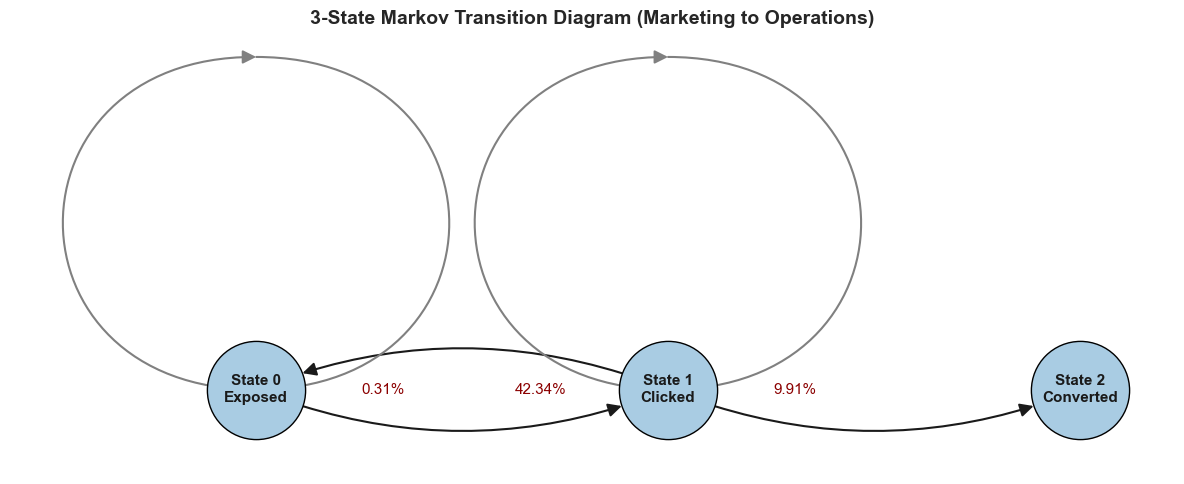

 Clean 3-State Diagram generated and saved!


In [12]:
import networkx as nx
import matplotlib.pyplot as plt

print("Generating clean 3-State Diagram...")

# Create a directed graph
G = nx.DiGraph()

# Nodes
G.add_node(0, label="State 0\nExposed")
G.add_node(1, label="State 1\nClicked")
G.add_node(2, label="State 2\nConverted")

# Edges with probabilities
edges = [
    (0, 0, f"{matrix_3x3.loc[0, 0]*100:.2f}%"),
    (0, 1, f"{matrix_3x3.loc[0, 1]*100:.2f}%"),
    (1, 0, f"{matrix_3x3.loc[1, 0]*100:.2f}%"),
    (1, 1, f"{matrix_3x3.loc[1, 1]*100:.2f}%"),
    (1, 2, f"{matrix_3x3.loc[1, 2]*100:.2f}%")
]
for u, v, label in edges:
    G.add_edge(u, v, label=label)

# Adjust positions to give more space
pos = {0: (0, 1), 1: (2, 1), 2: (4, 1)}

plt.figure(figsize=(12, 5))

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_size=5000, node_color='#A9CCE3', edgecolors='black')

# Draw labels
nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, 'label'), font_size=11, font_weight='bold')

# Draw straight edges (0->1, 1->0, 1->2)
nx.draw_networkx_edges(G, pos, edgelist=[(0,1), (1,0), (1,2)], 
                       arrowsize=20, width=1.5, node_size=5000, 
                       connectionstyle='arc3,rad=0.2')

# Draw self-loops (0->0, 1->1) with a larger curve to avoid overlapping
nx.draw_networkx_edges(G, pos, edgelist=[(0,0)], arrowsize=20, width=1.5, 
                       node_size=5000, connectionstyle='arc3,rad=1.5', edge_color='gray')
nx.draw_networkx_edges(G, pos, edgelist=[(1,1)], arrowsize=20, width=1.5, 
                       node_size=5000, connectionstyle='arc3,rad=1.5', edge_color='gray')

# Draw edge labels
edge_labels = {(u, v): label for u, v, label in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=11, 
                             font_color='darkred', label_pos=0.3)

plt.title("3-State Markov Transition Diagram (Marketing to Operations)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('Figure_5_3State_Diagram.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Clean 3-State Diagram generated and saved!")

In [13]:
import pandas as pd
import numpy as np

print("===  MODELING AD FATIGUE ===\n")

# 1. Create a copy of the combined data for the 3-state model
fatigue_df = combined_train[['timestamp', 'user_id', 'state']].copy()

# 2. We need to track consecutive exposures (state == 0)
# We create a helper column that is 1 if state==0, and 0 if state==1 (click)
fatigue_df['is_exposed'] = (fatigue_df['state'] == 0).astype(int)

# 3. We use a technique called "groupby and cumsum" to count consecutive exposures
# Every time there is a click (0), the cumsum resets for that user.
# This creates a count of how many exposures the user has seen in a row.
fatigue_df['consecutive_exposures'] = fatigue_df.groupby(['user_id', fatigue_df['state'].eq(1).groupby(fatigue_df['user_id']).cumsum()])['is_exposed'].cumsum()

# 4. Define the new states:
# If they clicked -> State 1 (Clicked)
# If they saw 3 or more consecutive exposures -> State 2 (Fatigued)
# Otherwise -> State 0 (Exposed/Normal)
conditions = [
    (fatigue_df['state'] == 1),
    (fatigue_df['consecutive_exposures'] >= 3)
]
choices = [1, 2] # 1=Clicked, 2=Fatigued
fatigue_df['fatigue_state'] = np.select(conditions, choices, default=0)

# 5. Extract the next state based on our new fatigue_state
fatigue_df['next_fatigue_state'] = fatigue_df.groupby('user_id')['fatigue_state'].shift(-1)
valid_fatigue_trans = fatigue_df.dropna(subset=['next_fatigue_state']).copy()
valid_fatigue_trans['next_fatigue_state'] = valid_fatigue_trans['next_fatigue_state'].astype(int)

# 6. Generate the new 3x3 Fatigue Matrix
fatigue_matrix = pd.crosstab(valid_fatigue_trans['fatigue_state'], valid_fatigue_trans['next_fatigue_state'], normalize='index')
fatigue_matrix = fatigue_matrix.reindex(index=[0, 1, 2], columns=[0, 1, 2]).fillna(0)

print("=== AD FATIGUE TRANSITION MATRIX ===")
print("States: 0=Normal Exposed, 1=Clicked, 2=Fatigued")
print(fatigue_matrix.round(4))

# 7. Calculate the Value of Retargeting a Fatigued User
# Probability of a Fatigued user clicking on the next impression:
fatigue_click_prob = fatigue_matrix.loc[2, 1]
print(f"\nProbability of a Fatigued User (State 2) clicking next: {fatigue_click_prob*100:.2f}%")

===  MODELING AD FATIGUE ===

=== AD FATIGUE TRANSITION MATRIX ===
States: 0=Normal Exposed, 1=Clicked, 2=Fatigued
next_fatigue_state      0       1       2
fatigue_state                            
0                   0.786  0.0030  0.2111
1                   0.470  0.5300  0.0000
2                   0.000  0.0038  0.9962

Probability of a Fatigued User (State 2) clicking next: 0.38%


Generating Ad Fatigue Chart...


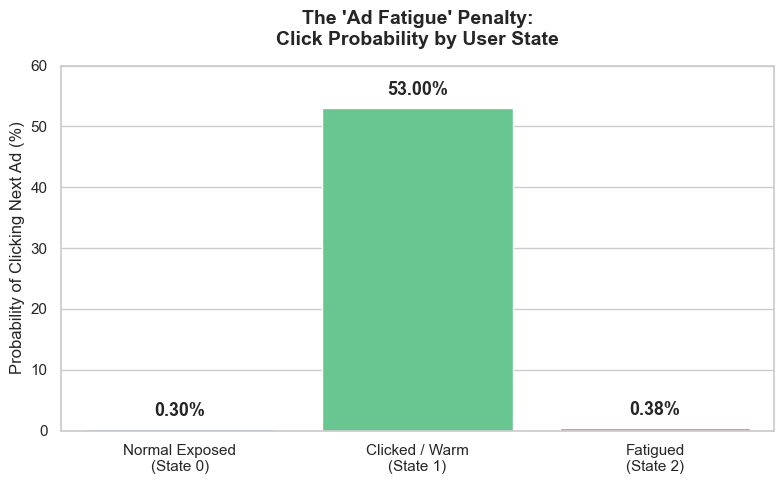

 Chart generated and saved as 'Figure_6_Ad_Fatigue_Penalty.png'


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generating Ad Fatigue Chart...")

# Data for the chart
states = ['Normal Exposed\n(State 0)', 'Clicked / Warm\n(State 1)', 'Fatigued\n(State 2)']
click_probs = [
    fatigue_matrix.loc[0, 1] * 100, # Prob of 0 -> 1
    fatigue_matrix.loc[1, 1] * 100, # Prob of 1 -> 1
    fatigue_matrix.loc[2, 1] * 100  # Prob of 2 -> 1
]

# Create the plot
plt.figure(figsize=(8, 5))
# Use a distinct color palette to highlight the 'Fatigued' state in red/warning color
colors = ['#5DADE2', '#58D68D', '#EC7063'] 

# Use the new seaborn syntax (hue=x, legend=False) to avoid warnings
bars = sns.barplot(x=states, y=click_probs, hue=states, palette=colors, legend=False)

plt.title("The 'Ad Fatigue' Penalty:\nClick Probability by User State", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Probability of Clicking Next Ad (%)", fontsize=12)

# Add the exact values on top of the bars
for i, v in enumerate(click_probs):
    plt.text(i, v + 1.5, f"{v:.2f}%", ha='center', va='bottom', fontsize=13, fontweight='bold')

plt.ylim(0, 60) # Set Y-axis limit to accommodate the 53% bar
plt.tight_layout()
plt.savefig('Figure_6_Ad_Fatigue_Penalty.png', dpi=300, bbox_inches='tight')
plt.show()

print(" Chart generated and saved as 'Figure_6_Ad_Fatigue_Penalty.png'")